# Mover una palanca de diseño a la vez: cómo responden tres brazos cuando cambian el bordo, el espaciamiento o el factor de carga

**Nivel 1: Fundamentos** · Requiere: 02-classical-prediction/01-the-classical-equation-on-one-blast, 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites · Tiempo de lectura: unos 25 minutos

## Objetivos

Un ingeniero de tronadura rara vez pide un solo número. La pregunta es qué pasa si se cierra el bordo, se abre el espaciamiento o se sube el factor de carga. El producto la responde perturbando una palanca de un diseño a la vez y prediciendo de nuevo, y muestra la respuesta de cada brazo. Este notebook hace eso para una campaña completa y tres tipos de brazo.

Al terminar habrá:

- aplicado las ocho variantes estándar del producto a los 22 tiros de Akdaglar y predicho cada uno con la ecuación clásica, la regresión publicada y un brazo aprendido;
- coincidido con las curvas de respuesta que versionó la ejecución offline;
- visto a qué palancas responde cada brazo, cuáles ignora, y por qué.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Esta celda aún no importa nada del notebook: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este notebook
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 22 tiros de Akdaglar | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| El registro de casos y las ocho variantes estándar | este repositorio (MIT) | la licencia propia del producto | `data-pipeline/pipeline/cases/fragmenta_cases.py`, importado por ruta |
| Las curvas de respuesta versionadas | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/real-akdaglar/case.json`, campo `variant_curves` |

Una variante mueve un campo de un tiro por un multiplicador y descarta el tamaño medido, porque un diseño perturbado no se ha disparado. La respuesta es una curva de predicciones, nunca puntuada contra la medición original.

## Método

Para cada variante `v` y cada tiro `b` del caso, `apply_variant(b, v)` devuelve una copia con un campo multiplicado, y el brazo la predice. La respuesta de un brazo a `v` es el tamaño medio predicho sobre los tiros del caso, de modo que la dispersión de la campaña se lleva a la curva en vez de reemplazarla por un tiro. Un diseño que deja de ser un tiro (por ejemplo, un taco más largo que el banco) lo omite `is_degenerate`, que el producto aplica antes de que corra cualquier brazo.

El módulo del pipeline se importa por su ruta, porque las variantes son parte del producto y no del motor. Los tres brazos se eligen para abarcar la escalera: la ecuación clásica (forma cerrada sobre geometría absoluta), la regresión publicada (una ley de potencia sobre las siete razones) y gradient boosting (un brazo aprendido, entrenado aquí sin Akdaglar).

### Paso 1: el caso, sus variantes y los brazos

La celda importa el registro, lista las ocho variantes del caso Akdaglar y construye los tres brazos. El brazo clásico recibe la tabla de factores de roca por sitio del motor, como hace `arm_catalogue` del producto.

In [2]:
# Importaciones, el registro del pipeline por ruta, las variantes del caso y los tres brazos
import json
import sys
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("../../../data-pipeline")))
from pipeline.model.blasts import apply_variant, blasts_for_case, is_degenerate
from pipeline.registry import get_case

DERIVED = Path("../../../data/derived")
case = get_case("real-akdaglar")
blasts = blasts_for_case(case)
print(case.title_en, "|", len(blasts), "tiros")
for variant in case.variants:
    print(f"  {variant.id:<14} {variant.field:<9} x {variant.factor:<5} {variant.label_en}")

train = bf.load_training_corpus()
arms = {
    "kuznetsov": bf.Kuznetsov(dict(bf.SITE_ROCK_FACTOR)),
    "published-regression": bf.PublishedRegression(),
    "xgboost": bf.default_arms()["xgboost"]().fit([b for b in train if b.site != case.site]),
}

Akdaglar quarry, Istanbul | 22 tiros
  base           none      x 1.0   As designed
  burden-tight   B_over_D  x 0.85  Burden 15 percent tighter
  burden-wide    B_over_D  x 1.15  Burden 15 percent wider
  spacing-wide   S_over_B  x 1.2   Spacing 20 percent wider
  powder-up      Pf_kg_m3  x 1.3   Powder factor 30 percent higher
  powder-down    Pf_kg_m3  x 0.75  Powder factor 25 percent lower
  stemming-long  T_over_B  x 1.25  Stemming 25 percent longer
  blocky         XB_m      x 1.5   In situ blocks 50 percent larger


### Paso 2: la respuesta de cada brazo

Para cada brazo y variante la celda perturba cada tiro del caso, omite los degenerados, predice y promedia las predicciones respondidas. Luego compara cada media con la curva que versionó la ejecución offline.

In [3]:
# El tamaño medio predicho por brazo y variante, y la mayor diferencia con las curvas versionadas
artifact = json.loads((DERIVED / "real-akdaglar" / "case.json").read_text(encoding="utf-8"))
response = {}
for name, arm in arms.items():
    response[name] = {}
    for variant in case.variants:
        sizes = []
        for blast in blasts:
            perturbed = apply_variant(blast, variant)
            if is_degenerate(perturbed) is not None:
                continue
            prediction = arm.predict_one(perturbed)
            if prediction.x50_m is not None:
                sizes.append(prediction.x50_m)
        response[name][variant.id] = sum(sizes) / len(sizes)
print(f"{'variante':<16}" + "".join(f"{name:>22}" for name in arms))
for variant in case.variants:
    print(f"{variant.id:<16}" + "".join(f"{response[name][variant.id]:>22.4f}" for name in arms))
gap = max(abs(response[n][v.id] - artifact["variant_curves"][n][v.id]) for n in arms for v in case.variants)
print("mayor diferencia con las curvas versionadas =", f"{gap:.1e}")

variante                     kuznetsov  published-regression               xgboost
base                            0.1593                0.1795                0.2454
burden-tight                    0.1469                0.1675                0.2524
burden-wide                     0.1709                0.1905                0.2441
spacing-wide                    0.1643                0.1983                0.2402
powder-up                       0.1349                0.1742                0.2456
powder-down                     0.1912                0.1855                0.2389
stemming-long                   0.1593                0.1755                0.2528
blocky                          0.1593                0.2140                0.2672
mayor diferencia con las curvas versionadas = 0.0e+00


### Paso 3: el cambio respecto del diseño base

Los tamaños absolutos esconden la palanca. La celda expresa cada variante como el cambio porcentual respecto del diseño base y lo dibuja para los tres brazos.

variante                     kuznetsov  published-regression               xgboost
burden-tight                     -7.8%                 -6.7%                 +2.9%
burden-wide                      +7.2%                 +6.1%                 -0.5%
spacing-wide                     +3.1%                +10.5%                 -2.1%
powder-up                       -15.3%                 -3.0%                 +0.1%
powder-down                     +20.0%                 +3.4%                 -2.6%
stemming-long                    +0.0%                 -2.2%                 +3.0%
blocky                           +0.0%                +19.2%                 +8.9%


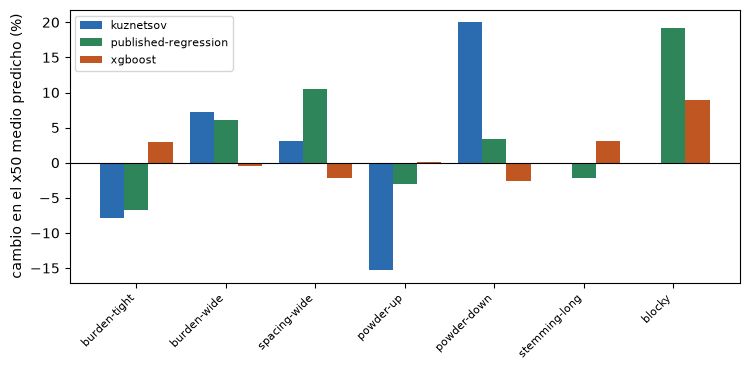

In [4]:
# Cambio porcentual del tamaño medio predicho respecto del diseño base, por brazo y variante
levers = [v for v in case.variants if v.id != "base"]
change = {n: [100 * (response[n][v.id] / response[n]["base"] - 1) for v in levers] for n in arms}
print(f"{'variante':<16}" + "".join(f"{name:>22}" for name in arms))
for k, variant in enumerate(levers):
    print(f"{variant.id:<16}" + "".join(f"{change[name][k]:>+21.1f}%" for name in arms))

fig, ax = plt.subplots(figsize=(7.6, 3.8))
x = np.arange(len(levers))
colors = {"kuznetsov": "#2b6cb0", "published-regression": "#2f855a", "xgboost": "#c05621"}
for k, name in enumerate(arms):
    ax.bar(x + (k - 1) * 0.27, change[name], 0.27, label=name, color=colors[name])
ax.set_xticks(x, [v.id for v in levers], rotation=45, ha="right", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("cambio en el x50 medio predicho (%)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

**Las curvas de respuesta son reproducibles.** Las respuestas de los tres brazos igualan las curvas versionadas hasta el redondeo del archivo, de modo que la vista de diseño de la aplicación web es una reproducción de este cálculo.

**La ecuación clásica responde a las palancas que la ecuación contiene.** Un bordo o espaciamiento mayor sube el tamaño predicho, un factor de carga mayor lo baja, uno menor lo sube. Dos variantes no hacen nada: un taco más largo y un bloque in situ mayor cambian el tamaño medio en exactamente cero, porque la ecuación clásica toma el factor de carga como dado y no tiene término para ninguno. El producto muestra esa respuesta plana como un hallazgo, no como una barra faltante.

**La regresión publicada y el brazo aprendido responden a otras palancas.** La regresión, una ley de potencia sobre las siete razones, responde a cada entrada que contiene, el taco y el bloque incluidos, con exponentes que se ajustaron en vez de derivarse. El brazo aprendido responde débil y desigualmente: un modelo de árboles es constante por tramos, así que un cambio pequeño a menudo cae dentro de una hoja y no hace nada, y uno mayor salta. En esta campaña incluso se mueve contra la mecánica para el bordo (un bordo más cerrado sube su predicción unos pocos por ciento) y casi no se mueve para el factor de carga, que la ecuación clásica trata como la palanca más fuerte.

**Qué no muestra esto.** Son respuestas de modelo, no resultados de tronadura. Ningún conjunto de datos registra el efecto de cambiar una palanca en un rajo dado, así que nada aquí dice cuál respuesta de brazo es correcta, y el producto etiqueta las curvas como la respuesta del modelo.

## Resumen

- Una variante mueve un campo por un multiplicador, descarta la medición y predice de nuevo; la respuesta de un brazo es la media sobre la campaña.
- La ecuación clásica ignora el taco y el bloque por construcción; la regresión y el brazo aprendido responden a palancas distintas, y un modelo de árboles responde por escalones.
- El notebook reproduce las curvas de respuesta versionadas.
- Siguiente: el notebook 02 barre dos palancas a la vez, el bordo y el espaciamiento, y compara las superficies.

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus y la regresión publicada)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (la ecuación clásica, en la que el factor de carga es una entrada)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (gradient boosting)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/